## Шаг №-1. Доустанавливала нужные модули:

In [481]:
pip install fake_useragent

In [482]:
pip install matplotlib

In [483]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


Вначале качаем нужные библиотеки:

In [484]:
import requests  # для самого краулера
from pprint import pprint
from fake_useragent import UserAgent
from bs4 import BeautifulSoup
import time
from datetime import datetime
import matplotlib.pyplot as plt  # для визуализации
import seaborn as sns
import pandas as pd
import re
import random
from collections import Counter
import tqdm
from tqdm.auto import tqdm

## Шаг №0. Проба пера
Хочется на пробу распарсить одну страничку, как делали на семинаре, чтобы лучше понимать работу сайта (я работаю с сайтом рецептов edimdoma :)). Задание будет в **шаге 1**, можно сразу искать его.

#### 0.1. Страница основного сайта
Вначале берём страничку и парсим ее бьютифулсупом.

In [485]:
# притворяемся нормальным браузером
session = requests.session()
ua = UserAgent()

In [486]:
page_number = 2  # выбрали страничку
url = f'https://www.edimdoma.ru/retsepty?page={page_number}'
req = session.get(url, headers={'User-Agent': ua.random})
page = req.text

In [487]:
soup = BeautifulSoup(page, 'html.parser')  # парсим её

Ищем всё, что подпадает под определение поста.

In [488]:
firstattempt = soup.find_all('article', {'class': 'card'})  # здесь я пробовала разные теги, пытаясь подобрать оптимальный для новостей (без рекламы и пр.)
specialcards = soup.find_all('article', {'class': 'card card-recipe-special'})
news = soup.find_all('article')
print(len(firstattempt))
print(len(specialcards))
print(len(news))

63
18
63


Оказывается, тег *article* обозначает любую ячейку для новости, в том числе рекламную. Попробуем собрать информацию из него, но исключить рекламные ячейки.

In [489]:
ads1 = soup.find_all('article', {'class': 'card card_commercial adfox_bn_tablet'})  # таки есть мешающие рекламные теги, будем потом чистить
ads2 = soup.find_all('article', {'class': 'card card_commercial adfox_bn_desktop'})
clearnews = [i for i in news if i not in ads1 and i not in ads2]
print(len(clearnews))

55


Теперь все правильно, совпадает с количеством новостей на странице :)

Достанем cсылку на статью:

In [490]:
title_obj = clearnews[0].find('a')
print(title_obj)

<a href="/retsepty/152584-pirozhki-iz-polenty-s-syrom-tvorogom-i-zelenyu"><picture class="card__picture"><img alt="Пирожки из поленты с сыром, творогом и зеленью" src="https://e1.edimdoma.ru/data/recipes/0015/2584/152584-ed4_wide.jpg?1698000350" title="Пирожки из поленты с сыром, творогом и зеленью"/></picture><div class="card__overlay"></div></a>


In [491]:
title_obj.attrs

{'href': '/retsepty/152584-pirozhki-iz-polenty-s-syrom-tvorogom-i-zelenyu'}

In [492]:
href = title_obj.attrs['href']  # извлекаем саму ссылку: по таким будем путешествовать в отдельные рецепты
print(href)

/retsepty/152584-pirozhki-iz-polenty-s-syrom-tvorogom-i-zelenyu


Попробуем добыть название:

In [493]:
title = clearnews[0].find('div', {'class': 'title'}).text  # есть отдельный тэг! не нужно извлекать из ссылки
print(title)

Пирожки  из поленты с сыром, творогом и зеленью


Достанем описание, которое влезает на сайт:

In [494]:
shorttext = clearnews[0].find('p', {'class': 'description-text'}).text  # но здесь оно будет обрезанное, поное -- внутри самой странички рецепта
print(shorttext)

Недавно открыла для себя поленту. И поняла, что из нее можно готовить выпечку. Решила поэкспериментировать и приготовила пирожки с творогом, сыром и


Достанем имя автора рецепта, а почему бы и нет:

In [495]:
author = clearnews[0].find('div', {'class': 'person__name'}).text
print(author)

Yana Ivanova


Достанем время публикации:

In [496]:
datepub = clearnews[0].find('time', {'class': 'person__post-time'}).text
print(datepub)

23 октября 2023 


#### 0.2. Попробуем парсить саму страницу, на которую переходим
Вначале качаем страницу и парсим её по соединённой ссылке.

In [497]:
url_o = "https://www.edimdoma.ru" + href
url_o

'https://www.edimdoma.ru/retsepty/152584-pirozhki-iz-polenty-s-syrom-tvorogom-i-zelenyu'

In [498]:
req = session.get(url_o, headers={'User-Agent': ua.random})
page = req.text

soup = BeautifulSoup(page, 'html.parser')

Отсюда можно взять полное описание, а не урезанную версию:

In [499]:
full = soup.find('div', {'class': 'recipe_description'}).text
print(full)

Недавно открыла для себя поленту. И поняла, что из нее можно готовить выпечку. Решила поэкспериментировать и приготовила пирожки с творогом, сыром и зеленью. Получилось очень вкусно, а самое главное — быстро готовится!



Можно взять список ингредиентов, и потом считать их частотность на сайте :) мне кажется, это веселее тэгов

In [500]:
meta = soup.find('div', {'id': 'recipe_ingredients_block'})  # извлекаем из кучи разных метаданных, механика похожа на тэги в новостях
ings = meta.find_all('span', {'class': 'recipe_ingredient_title'})
for i in ings:
    print(i.text)

полента
молоко
сыр
творог
укроп
чеснок
соль


## Шаг №1. Пишем функции для парсинга всего сайта

#### Нужна функция чистки страницы от рекламы

In [501]:
def cleanpage(beausoup):  # берём на вход распаршенную страницу сайта
    rawnews = beausoup.find_all('article')  # находим рецепты, помним, что их надо почистить от рекламы
    deskads = beausoup.find_all('article', {'class': 'card card_commercial adfox_bn_tablet'})  # полагаю, на сайте есть слоты для мобильной рекламы
    mobads = beausoup.find_all('article', {'class': 'card card_commercial adfox_bn_desktop'})  # и десктопной
    clearnews = [i for i in rawnews if i not in deskads and i not in mobads]
    return clearnews

#### Перевод даты словами в дату цифрами

In [502]:
months = {
    value: key + 1
    for key, value in enumerate(
        ['января', 'февраля', 'марта', 'апреля', 'мая', 'июня', 'июля', 'августа', 'сентября', 'октября', 'ноября', 'декабря']
    )
}

#### Функция парсинга одного блока рецепта на общей странице
Хочется название, ссылку, автора и дату публикации. Может быть, пометку "особенности" рецепта. Описание брать отсюда смысла не особо имеет, поскольку это урезаная (часто посередине слова) версия описания, которое будет внутри самой странички рецепта.

In [503]:
def parse_recipe_from_all(one_block):  # здесь на вход берем объект из класса card из очищенного от рекламы списка
    block = {}
    block['title'] = title = one_block.find('div', {'class': 'title'}).text  # находим название: здесь оно в отдельном теге, не в списке
    block['href'] =  one_block.find('a').attrs['href']  # находим ссылку, будем её хранить в табличке
    block['author'] = one_block.find('div', {'class': 'person__name'}).text
    date = one_block.find('time', {'class': 'person__post-time'}).text.split(' ')  # в тексте дата указана строкой, так что надо её аккуратно разбить
    block['pub_day'] = int(date[0])
    block['pub_month'] = months[date[1]]
    block['pub_year'] = int(date[2])
    return block

#### Функция парсинга одного рецепта на его собственной странице
Хочется полное описание и список ингредиентов

In [504]:
def parse_recipe_page(block):  # подаём на вход словарь рецепта из прошлой функции
    url_one = 'https://www.edimdoma.ru' + block['href']  # парсим страницу после перехода по ссылке
    req = session.get(url_one, headers={'User-Agent': ua.random})
    page = req.text
    soup = BeautifulSoup(page, 'html.parser')
    descr = soup.find('div', {'class': 'recipe_description'})
# не у всех рецептов есть описание, и от его отсутствия код расстраивается, поскольку другой тип. так что надо ставить условия:
    if str(type(descr)) == "<class 'bs4.element.Tag'>":
        block['description'] = soup.find('div', {'class': 'recipe_description'}).text  # нашли описание
    else:
        block['description'] = ''
    meta = soup.find('div', {'id': 'recipe_ingredients_block'})  # находим список ингредиентов
    ings = meta.find_all('span', {'class': 'recipe_ingredient_title'})
    block['ingredients'] = [t.text for t in ings]     
    return block

#### Функция парсинга страницы новостей
То, как вся страница будет обработана

In [505]:
def get_nth_page(num):
    ssyl = f'https://www.edimdoma.ru/retsepty?page={num}'  # скачиваем всю страницу рецептов
    requ = session.get(ssyl, headers={'User-Agent': ua.random})  # притворяемся браузером
    page = requ.text
    soupec = BeautifulSoup(page,'html.parser')
    newsfunc = cleanpage(soupec)  # очищаем новости от рекламы
    recipesfrompage = []  # здесь будут данные с общей страницы, где только карточки рецептов
    exceptions = []  # а здесь будем записывать то, что не записалось
    for n in newsfunc:  # анализируем с общей странички
        try:
            parsedblock = parse_recipe_from_all(n)
            recipesfrompage.append(parsedblock)
        except Exception as e:
            exceptions.append(e)
    itogforpage = []
    for res in recipesfrompage:  # бегаем по внутренностям рецептов и парсим информацию оттуда
        try:
            allrecipeinfo = parse_recipe_page(res)
            itogforpage.append(allrecipeinfo)
        except Exception as e:
            exceptions.append(e)
    return [itogforpage, exceptions]

## Шаг №2. Скидываем всё в датафрейм

#### Функция, куда мы всё скидываем и она считывает информацию со многих страниц разом
На странице 55 рецептов, следовательно, 20 страниц будет более чем достаточно.

In [506]:
def run_all(n_pages):
    allposts = []  # вся информация со всех страниц
    allexcepts = []  # все исключения
    for i in tqdm(range(n_pages)):
        allposts.extend(get_nth_page(i+1)[0])
        allexcepts.extend(get_nth_page(i+1)[1])
    return [allposts, allexcepts]

In [507]:
recipes = run_all(20)[0]  # нам нужны тут пока что только сами данные, исключения -- в следующей ячейке

  0%|          | 0/20 [00:00<?, ?it/s]

In [514]:
df = pd.DataFrame(recipes)  # вкидываем всё в датасет
df.to_csv('20pagesofedimdoma.csv', encoding = "utf-8")

In [508]:
expsall = run_all(20)[1]  # а вот и исключения
print(expsall)

  0%|          | 0/20 [00:00<?, ?it/s]

[ConnectionError(ProtocolError('Connection aborted.', RemoteDisconnected('Remote end closed connection without response')))]


## Шаг №3. Считаем статистику (самые популярные игредиенты, количество постов по месяцам)

In [509]:
print("Cамые популярные ингредиенты:\n")  # посчитаем через каунтер самые популярные элементы столбца ингредиентс
ing_counts = {}
ingrs = [x for xs in df["ingredients"] for x in xs]
for title, counts in sorted(Counter(ingrs).items(), key=lambda x: -x[-1])[:15]:
    ing_counts[title] = counts  # заполняем данными словарь
    print(counts,"\t", title)
print("\nCамые активные авторы:\n")  # аналогично с авторами
auth_counts = {}
authors = df["author"]
for title, counts in sorted(Counter(authors).items(), key=lambda x: -x[-1])[:20]:
    auth_counts[title] = counts
    print(counts,"\t", title)
print("\nКол-во постов по месяцам:\n")  # просто выведем методами датасета количество постов, которые были выложены на сайте в разные месяцы
df.groupby("pub_month")["title"].count()

Cамые популярные ингредиенты:

660 	 соль
482 	 сахар
418 	 яйца куриные
386 	 сливочное масло
285 	 мука
285 	 чеснок
228 	 вода
223 	 лук репчатый
194 	 оливковое масло
178 	 растительное масло
171 	 соль морская
151 	 перец черный свежемолотый
147 	 морковь
147 	 разрыхлитель
136 	 молоко

Cамые активные авторы:

183 	 Юлия Высоцкая
128 	 Т
108 	 alla_33
105 	 Галина
95 	 Едим Дома
79 	 bellaira
54 	 michsenkoea
30 	 Елена
29 	 Güiña
25 	 @krisstinii
24 	 Simona
22 	 Лилия
22 	 Марфа
15 	 REDMOND
12 	 ulay_86
10 	 daiquiri
10 	 Hochland
10 	 СберМаркет
9 	 Щедрые
9 	 Виктория

Кол-во постов по месяцам:



pub_month
1      56
2     102
3      74
4      81
5      62
6      55
7      76
8      92
9     147
10    151
11    113
12     91
Name: title, dtype: int64

## Шаг №4. Визуализация

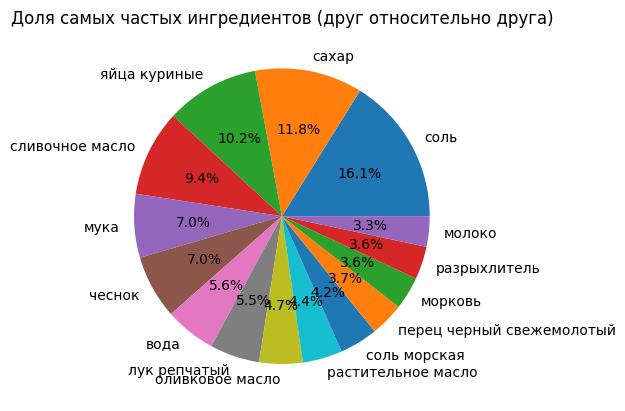

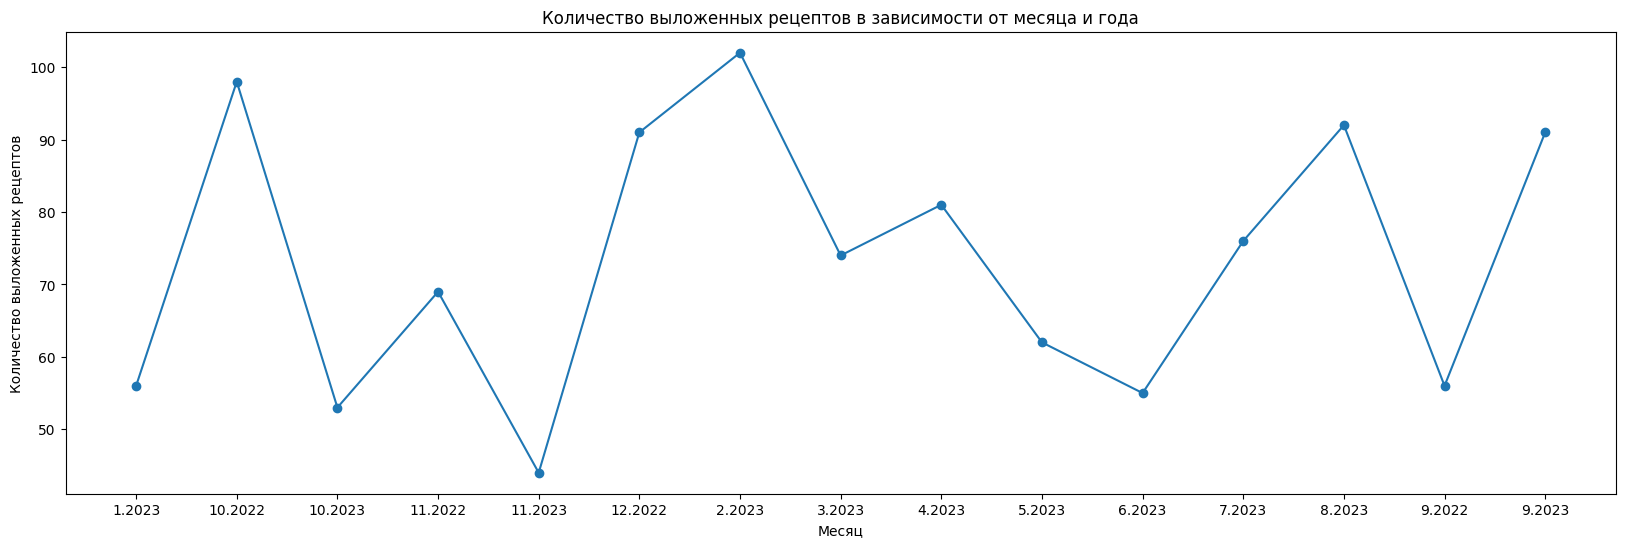

pub_month
1      56
2     102
3      74
4      81
5      62
6      55
7      76
8      92
9     147
10    151
11    113
12     91
dtype: int64


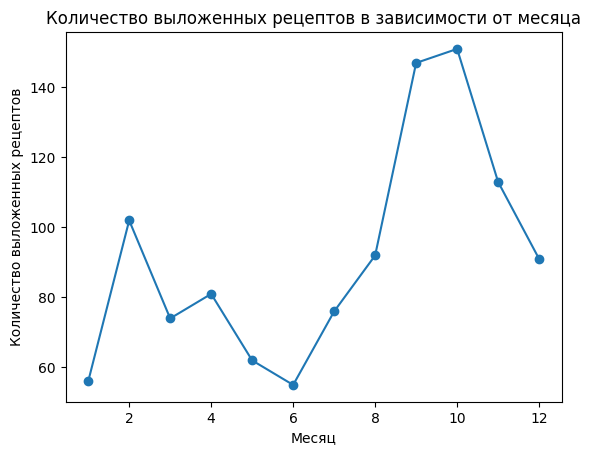

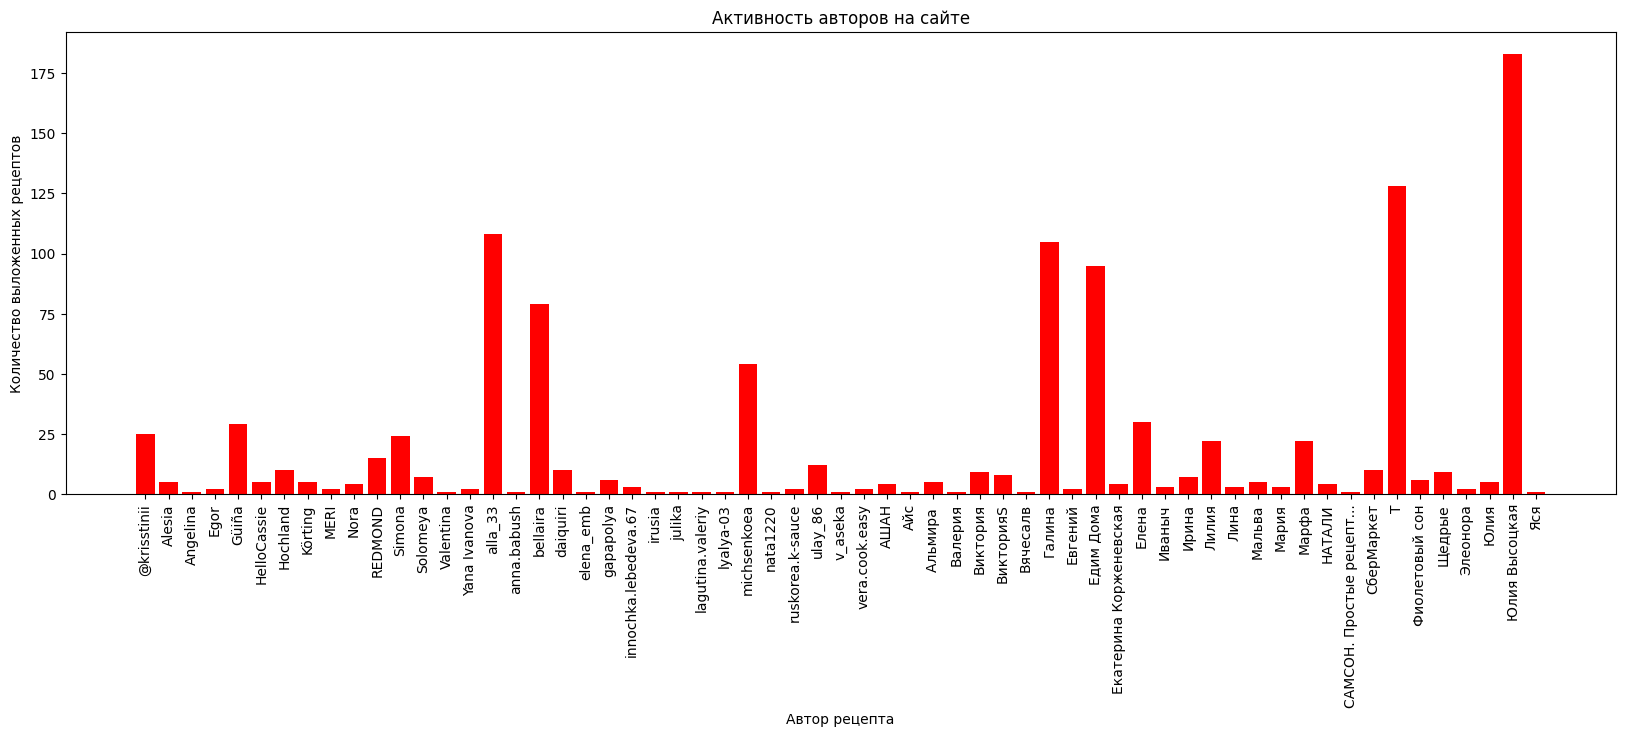

In [512]:
# pie plot для десяти самых популярных ингредиентов, которые мы посчитали: соль среди них занимает долю частотности 16 процентов, сахар -- 11 и т.д.
df_ing = pd.DataFrame.from_dict(ing_counts, orient='index', columns=['count'])
plt.pie(df_ing['count'], labels=df_ing.index, autopct='%1.1f%%')
plt.title('Доля самых частых ингредиентов (друг относительно друга)')
plt.show()

# У меня не получилось красиво расположить точки на первом линейном графике, чтобы оно всё было расположено в хронологическом порядке, поскольку
# я не осознала причин, по которым они перепутались in the first place. В качестве компенсации для себя самой сделала второй график с общими
# суммами постов по месяцам.

# line plot для того, как много рецептов было выложено в каждый месяц каждого года: в нашей выборке больше всего постов относится к февралю 2022 года
df_new = df.copy()
df_new['monthofyear'] = df_new['pub_month'].astype(str) + '.' + df_new['pub_year'].astype(str)
numofrecipes = df_new.groupby('monthofyear').size()
plt.figure(figsize=(20,6))
df_new.to_csv('helpful.csv', encoding = "utf-8")
plt.plot(numofrecipes.index, numofrecipes.values, marker='o')
plt.xlabel('Месяц')
plt.ylabel('Количество выложенных рецептов')
plt.title('Количество выложенных рецептов в зависимости от месяца и года')
plt.show()

# line plot для того, как много рецептов было выложено по месяцам вообще: в нашей выборке больше всего активности пользователи проявляли в октябре
numoverall = df.groupby('pub_month').size()
print(numoverall)
plt.plot(numoverall.index, numoverall.values, marker='o')
plt.xlabel('Месяц')
plt.ylabel('Количество выложенных рецептов')
plt.title('Количество выложенных рецептов в зависимости от месяца')
plt.show()

# bar plot для демонстрации активности разных авторов рецептов: активнее всех были Юлия Высоцкая, а также Т, Галина, ЕдимДома и alla_33
popularity = pd.DataFrame.from_dict(authors).reset_index()
popularity.columns = ['posts', 'author']
grouped = popularity.groupby('author').size().reset_index(name='number')
plt.figure(figsize=(20,6))
plt.xticks(rotation=90)
plt.bar(grouped['author'], grouped['number'], color='red')
plt.xlabel('Автор рецепта')
plt.ylabel('Количество выложенных рецептов')
plt.title('Активность авторов на сайте')
plt.show()